# 05 | Country subsets (Portugal and Spain)

Splits the PT + ES layers into separate Portugal and Spain layers, with and without archipelagos.

| Table | Filter used |
|---|---|
| Postal codes | `NUTS0_ID == "PT"` or `"ES"` |
| Localities | `LocalityID` starts with `PT_` or `ES_` |
| NUTS 1, 2, 3 | NUTS ID starts with `PT` or `ES` |

The districts and municipalities of Portugal were already created in notebook 03.

## Setup

In [1]:
import sys
from pathlib import Path

# Make the src/ folder importable when running from the notebooks/ folder
sys.path.append(str(Path.cwd().parent))

import geopandas as gpd
import numpy as np
import pandas as pd

from src.utils import *

In [2]:
layers_with_archipelagos = {
    "PostalCodes": load_layer("PostalCodes2024_PT_ES"),
    "Localities": load_layer("Localities2024_PT_ES"),
    "NUTS1": load_layer("NUTS1_2024_PT_ES"),
    "NUTS2": load_layer("NUTS2_2024_PT_ES"),
    "NUTS3": load_layer("NUTS3_2024_PT_ES"),
}

layers_mainland = {
    "PostalCodes": load_layer("PostalCodes2024_PT_ES_mainland"),
    "Localities": load_layer("Localities2024_PT_ES_mainland"),
    "NUTS1": load_layer("NUTS1_2024_PT_ES_mainland"),
    "NUTS2": load_layer("NUTS2_2024_PT_ES_mainland"),
    "NUTS3": load_layer("NUTS3_2024_PT_ES_mainland"),
}

In [3]:
def filter_country(gdf, table, country):
    """Keep only the rows of one country ("PT" or "ES")."""
    if table == "PostalCodes":
        mask = gdf["NUTS0_ID"] == country
    elif table == "Localities":
        mask = gdf["LocalityID"].astype(str).str.startswith(country + "_")
    else:  # NUTS1, NUTS2, NUTS3
        mask = gdf[f"{table}_ID"].astype(str).str.startswith(country)
    return gdf[mask].copy()

## Create and save the subsets

In [4]:
# Start of the output layer name for each table type
name_prefix = {"PostalCodes": "PostalCodes2024", "Localities": "Localities2024", "NUTS1": "NUTS1_2024", "NUTS2": "NUTS2_2024", "NUTS3": "NUTS3_2024"}

for country in ["PT", "ES"]:
    for table, gdf in layers_with_archipelagos.items():
        save_layer(filter_country(gdf, table, country), f"{name_prefix[table]}_{country}")

    for table, gdf in layers_mainland.items():
        save_layer(filter_country(gdf, table, country), f"{name_prefix[table]}_{country}_mainland")

Saved layer 'PostalCodes2024_PT' (198401 rows)
Saved layer 'Localities2024_PT' (3092 rows)
Saved layer 'NUTS1_2024_PT' (3 rows)
Saved layer 'NUTS2_2024_PT' (9 rows)
Saved layer 'NUTS3_2024_PT' (26 rows)
Saved layer 'PostalCodes2024_PT_mainland' (189516 rows)
Saved layer 'Localities2024_PT_mainland' (2882 rows)
Saved layer 'NUTS1_2024_PT_mainland' (1 rows)
Saved layer 'NUTS2_2024_PT_mainland' (7 rows)
Saved layer 'NUTS3_2024_PT_mainland' (24 rows)
Saved layer 'PostalCodes2024_ES' (11428 rows)
Saved layer 'Localities2024_ES' (8132 rows)
Saved layer 'NUTS1_2024_ES' (7 rows)
Saved layer 'NUTS2_2024_ES' (19 rows)
Saved layer 'NUTS3_2024_ES' (59 rows)
Saved layer 'PostalCodes2024_ES_mainland' (10862 rows)
Saved layer 'Localities2024_ES_mainland' (7975 rows)
Saved layer 'NUTS1_2024_ES_mainland' (6 rows)
Saved layer 'NUTS2_2024_ES_mainland' (15 rows)
Saved layer 'NUTS3_2024_ES_mainland' (47 rows)


## Visual validation

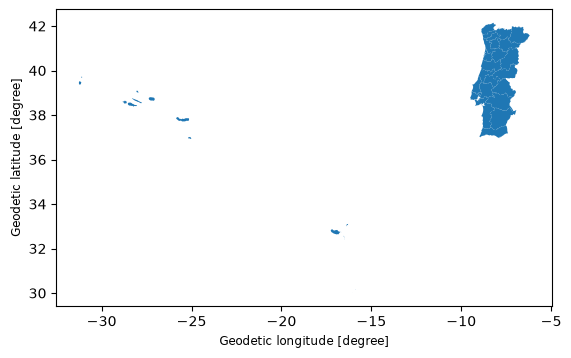

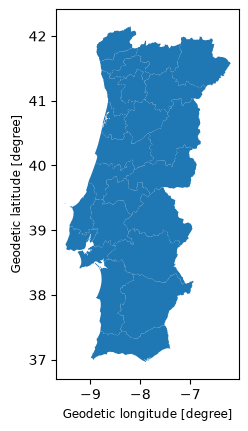

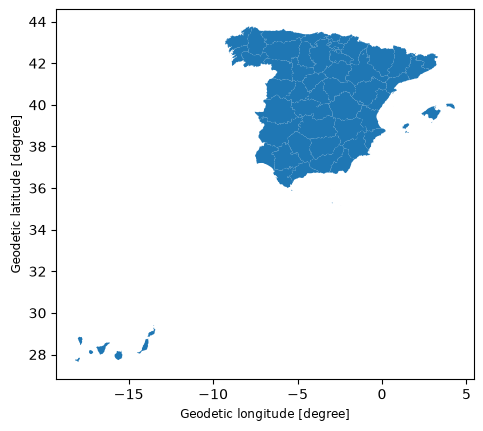

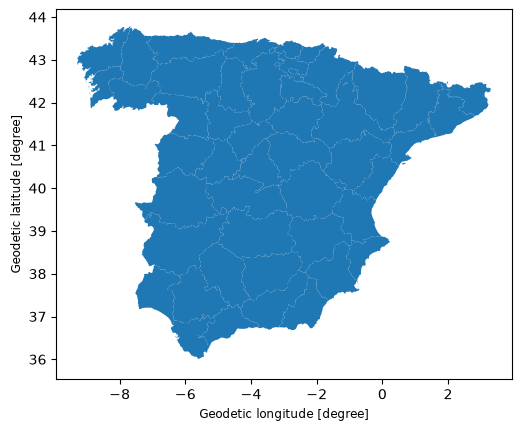

In [5]:
load_layer("NUTS3_2024_PT").plot();
load_layer("NUTS3_2024_PT_mainland").plot();
load_layer("NUTS3_2024_ES").plot();
load_layer("NUTS3_2024_ES_mainland").plot();

## Summary
* Filtered the postal codes, localities and NUTS 1, 2 and 3 layers by country, using the same rule for each table type.
* Created four versions of each table: Portugal, mainland Portugal, Spain and mainland Spain.
* Checked the results visually (the mainland versions must not show the Azores, Madeira, Canary Islands, Balearic Islands, Ceuta or Melilla).